In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 32
epochs = 10

In [ ]:
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.GTSRB(root='./data', split='train', download=True, transform=transform_train)
test_dataset = datasets.GTSRB(root='./data', split='test', download=True, transform=transform_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

num_classes = 43 # O dataset GTSRB possui 43 classes de placas

100%|██████████| 187M/187M [00:15<00:00, 12.3MB/s]
100%|██████████| 89.0M/89.0M [00:12<00:00, 7.37MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 180kB/s]


In [ ]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for param in model.parameters():
    param.requires_grad = False

num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()

# Experimento: Alterne entre Adam e SGD comentando/descomentando as linhas abaixo
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)
# optimizer = optim.SGD(model.fc.parameters(), lr=0.001, momentum=0.9)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 236MB/s]


Época 1/10 - Loss: 1.6151
Época 2/10 - Loss: 0.9414
Época 3/10 - Loss: 0.7803
Época 4/10 - Loss: 0.7075
Época 5/10 - Loss: 0.6534
Época 6/10 - Loss: 0.6141
Época 7/10 - Loss: 0.5895
Época 8/10 - Loss: 0.5668
Época 9/10 - Loss: 0.5387
Época 10/10 - Loss: 0.5316


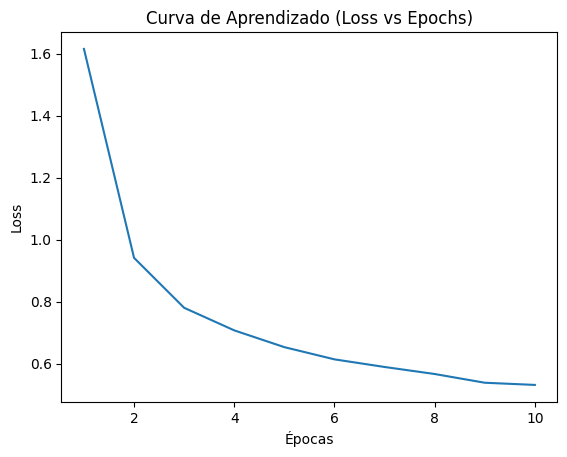

In [ ]:
model.train()
loss_history = []

for epoch in range(epochs):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    loss_history.append(epoch_loss)
    print(f"Época {epoch+1}/{epochs} - Loss: {epoch_loss:.4f}")

plt.plot(range(1, epochs + 1), loss_history)
plt.title('Curva de Aprendizado (Loss vs Epochs)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.show()

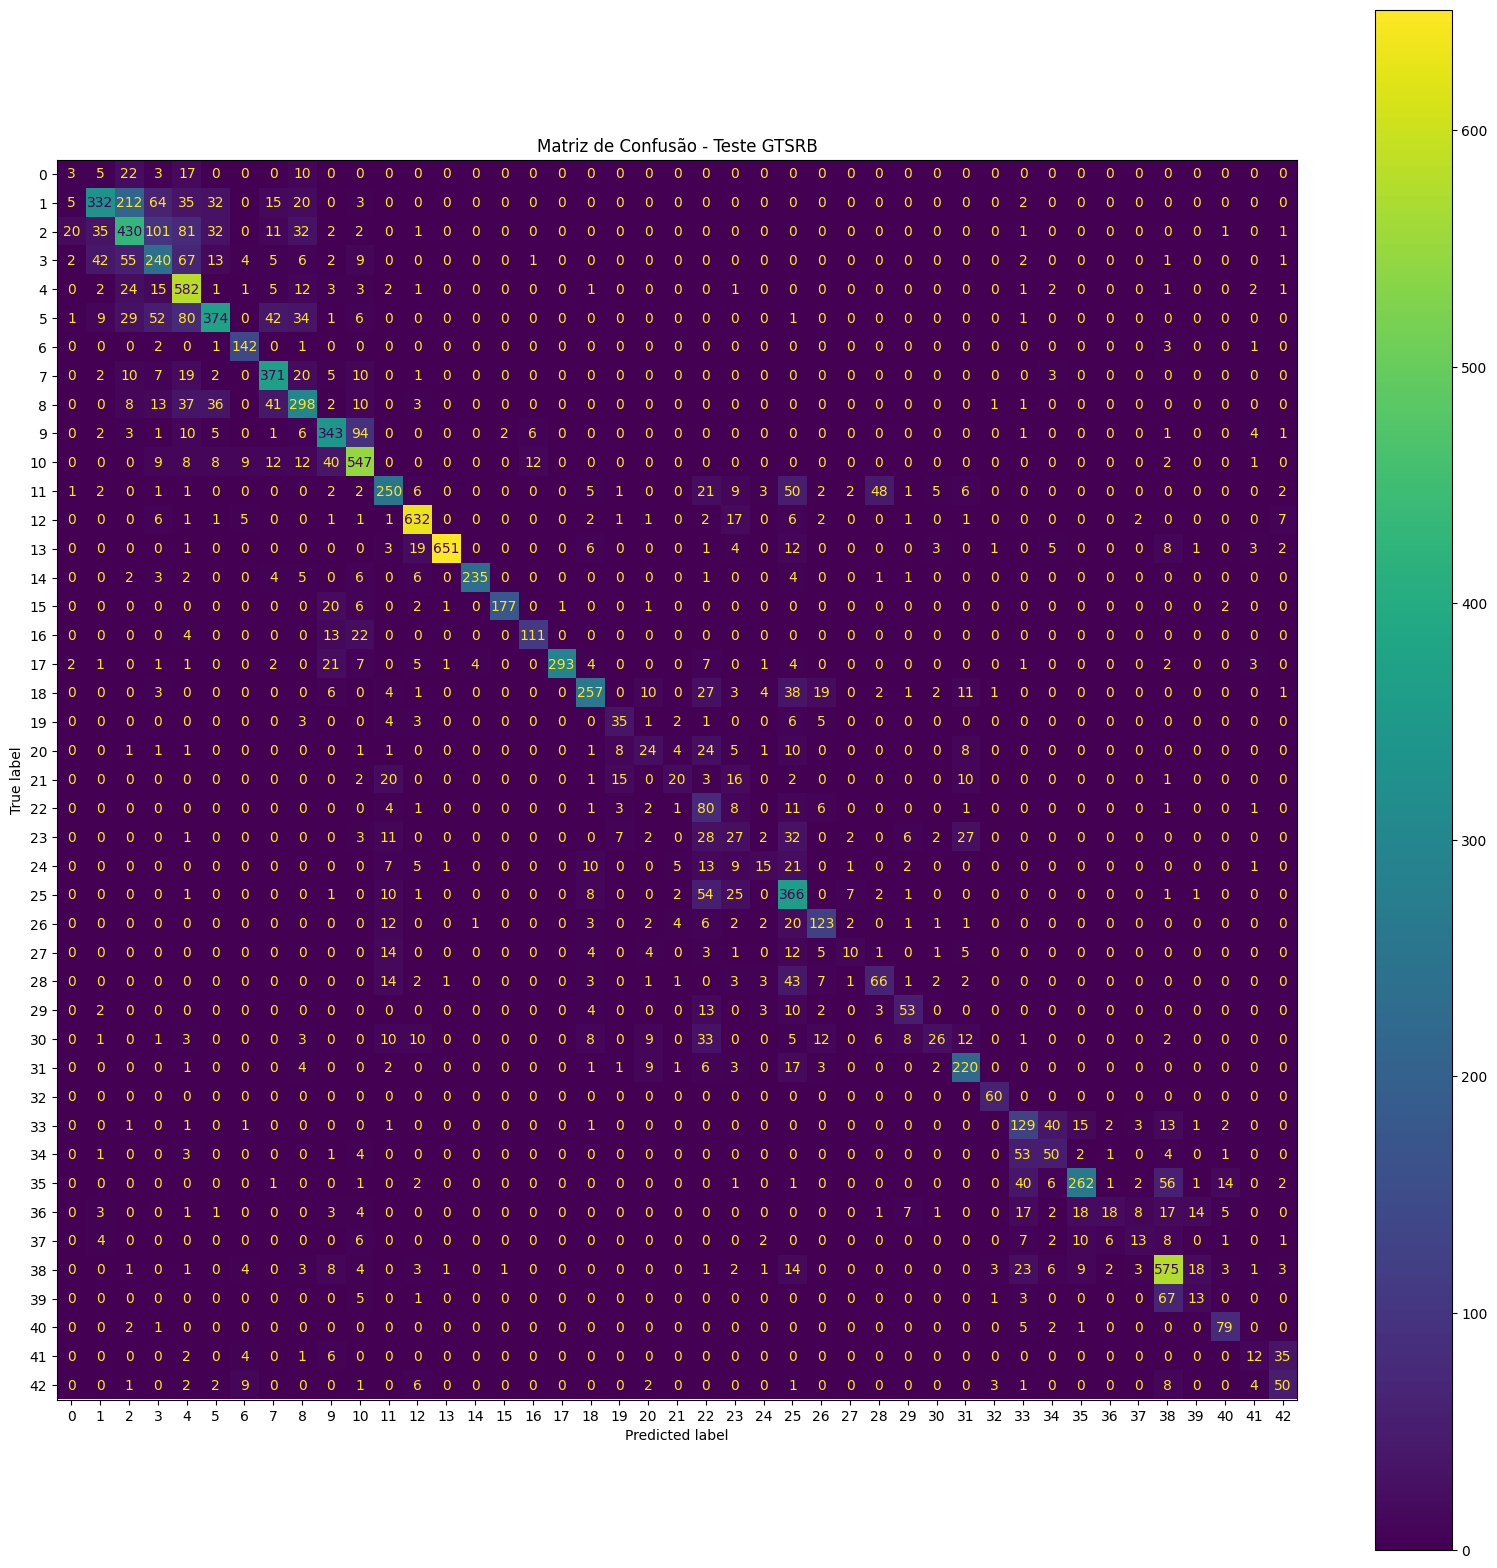

In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(20, 20))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(ax=ax, cmap='viridis')
plt.title('Matriz de Confusão - Teste GTSRB')
plt.show()

Mounted at /content/drive


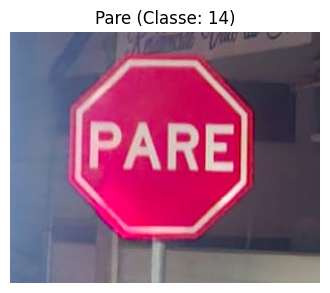

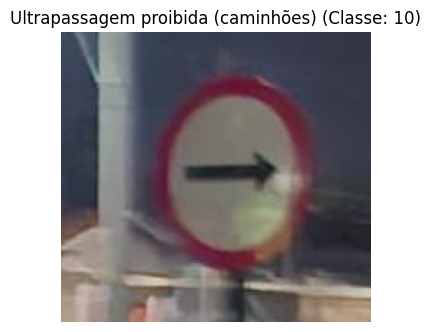

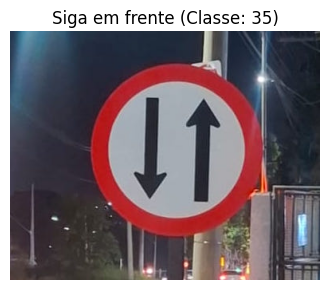

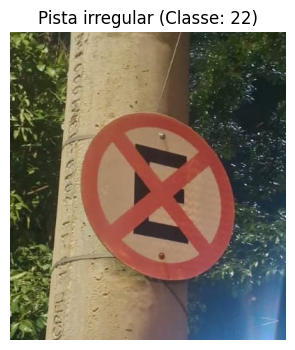

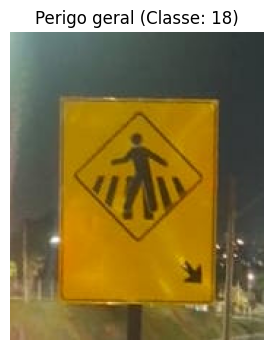

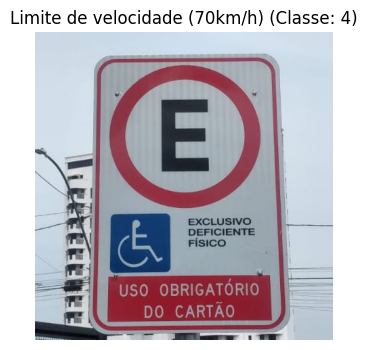

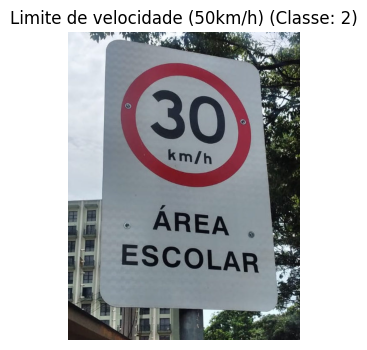

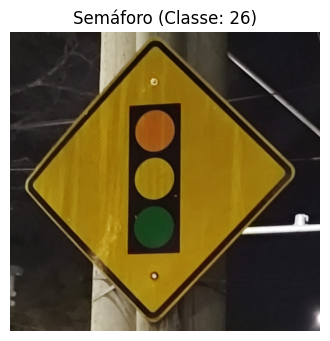

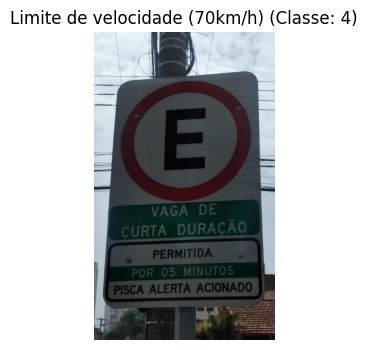

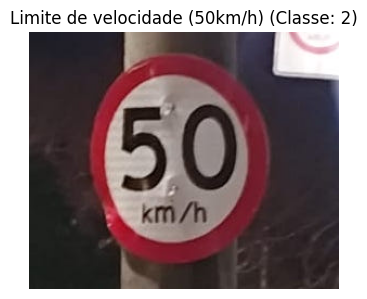

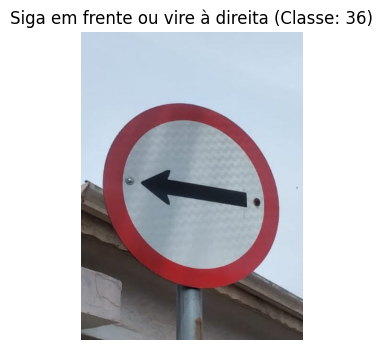

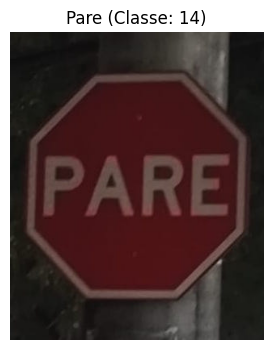

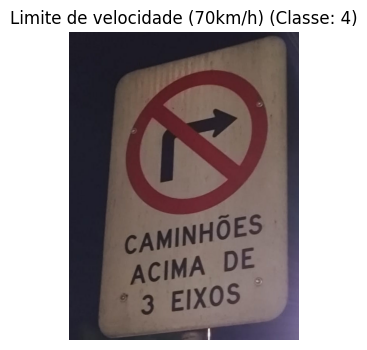

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Dicionário mapeando os 43 IDs oficiais do GTSRB para os nomes em português
gtsrb_classes = {
    0: 'Limite de velocidade (20km/h)', 1: 'Limite de velocidade (30km/h)', 2: 'Limite de velocidade (50km/h)',
    3: 'Limite de velocidade (60km/h)', 4: 'Limite de velocidade (70km/h)', 5: 'Limite de velocidade (80km/h)',
    6: 'Fim do limite de vel. (80km/h)', 7: 'Limite de velocidade (100km/h)', 8: 'Limite de velocidade (120km/h)',
    9: 'Ultrapassagem proibida', 10: 'Ultrapassagem proibida (caminhões)', 11: 'Cruzamento com via secundária',
    12: 'Via preferencial', 13: 'Dê a preferência', 14: 'Pare', 15: 'Trânsito proibido',
    16: 'Proibido trânsito de caminhões', 17: 'Sentido proibido (Não entre)', 18: 'Perigo geral',
    19: 'Curva perigosa à esquerda', 20: 'Curva perigosa à direita', 21: 'Curva sinuosa',
    22: 'Pista irregular', 23: 'Pista escorregadia', 24: 'Estreitamento de pista à direita',
    25: 'Obras na pista', 26: 'Semáforo', 27: 'Trânsito de pedestres', 28: 'Crianças brincando',
    29: 'Trânsito de bicicletas', 30: 'Cuidado: Gelo/Neve', 31: 'Travessia de animais selvagens',
    32: 'Fim das restrições', 33: 'Vire à direita à frente', 34: 'Vire à esquerda à frente',
    35: 'Siga em frente', 36: 'Siga em frente ou vire à direita', 37: 'Siga em frente ou vire à esquerda',
    38: 'Mantenha-se à direita', 39: 'Mantenha-se à esquerda', 40: 'Rotatória',
    41: 'Fim da proib. de ultrapassagem', 42: 'Fim da proib. de ultrapassagem (caminhões)'
}

# Monta o Google Drive (necessário para acessar as fotos de teste)
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

pasta_imagens = "/content/drive/MyDrive/projeto_final_IA/img"

model.eval()

with torch.no_grad():
    for nome_arquivo in os.listdir(pasta_imagens):
        if nome_arquivo.lower().endswith(('.png', '.jpg', '.jpeg')):
            caminho_completo = os.path.join(pasta_imagens, nome_arquivo)

            imagem_pil = Image.open(caminho_completo).convert('RGB')
            imagem_tensor = transform_test(imagem_pil)
            imagem_tensor = imagem_tensor.unsqueeze(0).to(device)

            outputs = model(imagem_tensor)
            _, pred = torch.max(outputs, 1)
            classe_predita = pred.item()

            nome_da_placa = gtsrb_classes.get(classe_predita, "Desconhecida")

            # Plota a imagem no output da célula
            plt.figure(figsize=(4, 4))
            plt.imshow(imagem_pil)
            plt.title(f"{nome_da_placa} (Classe: {classe_predita})")
            plt.axis('off')  # Oculta os eixos X e Y
            plt.show()

## Experimento: Adam × SGD com Momentum

**Objetivo:** comparar dois otimizadores mantendo **todos os outros hiperparâmetros iguais**: mesmo modelo (ResNet18 pré-treinada com as camadas congeladas), mesma taxa de aprendizado (`lr = 0.001`), mesmo `batch_size = 32`, mesmo número de épocas (`10`), mesmas transformações e mesma semente aleatória. Assim, qualquer diferença no resultado vem só do otimizador.

> Cada otimizador treina um **modelo novo**, criado do zero. Se reaproveitássemos o mesmo modelo, o segundo otimizador começaria de pesos já treinados pelo primeiro e a comparação seria injusta.

### Diferenças entre os otimizadores

| | **SGD com Momentum** | **Adam** |
|---|---|---|
| Ideia | Desce na direção do gradiente e acumula uma "velocidade" (momentum = 0.9) que suaviza oscilações e acelera em direções consistentes | Combina momentum com uma taxa de aprendizado **adaptativa por parâmetro**, baseada na média dos gradientes e dos gradientes ao quadrado |
| Taxa de aprendizado | A mesma para todos os pesos | Ajustada automaticamente para cada peso |
| Sensibilidade ao `lr` | Alta: com lr pequeno costuma convergir devagar | Baixa: funciona bem com o padrão 0.001 |
| Velocidade de convergência | Geralmente mais lenta no início | Geralmente mais rápida no início |
| Generalização | Muitas vezes generaliza um pouco melhor em treinos longos | Pode estabilizar antes, às vezes com generalização um pouco pior |

**Hipótese:** com `lr = 0.001`, que é o valor padrão do Adam mas é baixo para o SGD, o Adam deveria reduzir a loss mais rápido e alcançar uma acurácia maior em 10 épocas.

### Resultados

| Otimizador | Loss na época 1 | Loss final (época 10) | Acurácia no teste | Tempo de treino |
|---|---|---|---|---|
| Adam | 1,6411 | **0,5357** | **67,64%** | 14,5 min |
| SGD + Momentum | 2,2164 | 0,7651 | 66,71% | **13,4 min** |

### Análise

- **Convergência:** o Adam convergiu bem mais rápido. Já na 1ª época a loss dele (1,64) era menor que a do SGD (2,22), e o SGD terminou a 10ª época (0,77) num patamar que o Adam já tinha atingido por volta da 3ª (0,78). Isso confirma a hipótese: a taxa de aprendizado adaptativa do Adam compensa o `lr` baixo, enquanto o SGD avança com passos pequenos e iguais para todos os pesos.
- **Acurácia:** apesar da diferença na loss, a acurácia de teste ficou praticamente igual (**67,64% × 66,71%**, menos de 1 ponto percentual). A curva do SGD ainda estava caindo na época 10, ou seja, com mais épocas ou um `lr` maior (ex.: 0,01) ele provavelmente alcançaria o Adam.
- **Por que os dois param perto de 67%?** O limite não está no otimizador, e sim no **modelo**: com as camadas convolucionais congeladas, só a última camada é treinada, e as features do ImageNet não separam bem placas muito parecidas (como os limites de velocidade). Os dois otimizadores chegam ao mesmo "teto" imposto pelo congelamento.
- **Tempo:** o SGD foi cerca de 1 minuto mais rápido (13,4 × 14,5 min). Ele faz menos contas por passo, porque o Adam guarda e atualiza duas médias para cada peso. Como só a camada final é treinada, a diferença é pequena e pode variar entre execuções.

**Conclusão:** com os mesmos hiperparâmetros, o **Adam convergiu mais rápido** (loss final 0,54 contra 0,77), mas a **acurácia final foi praticamente a mesma** (67,6% contra 66,7%). Em 10 épocas com `lr = 0,001`, o Adam é a escolha mais prática. Para melhorar de fato a acurácia, o próximo passo seria descongelar a rede (fine-tuning completo), já que o otimizador não é o gargalo.

[Adam] Época 1/10 - Loss: 1.6411
[Adam] Época 2/10 - Loss: 0.9519
[Adam] Época 3/10 - Loss: 0.7842
[Adam] Época 4/10 - Loss: 0.7041
[Adam] Época 5/10 - Loss: 0.6546
[Adam] Época 6/10 - Loss: 0.6144
[Adam] Época 7/10 - Loss: 0.5984
[Adam] Época 8/10 - Loss: 0.5678
[Adam] Época 9/10 - Loss: 0.5482
[Adam] Época 10/10 - Loss: 0.5357
[Adam] Acurácia no teste: 67.64% | Tempo: 14.5 min

[SGD + Momentum] Época 1/10 - Loss: 2.2164
[SGD + Momentum] Época 2/10 - Loss: 1.4372
[SGD + Momentum] Época 3/10 - Loss: 1.1971
[SGD + Momentum] Época 4/10 - Loss: 1.0647
[SGD + Momentum] Época 5/10 - Loss: 0.9765
[SGD + Momentum] Época 6/10 - Loss: 0.9132
[SGD + Momentum] Época 7/10 - Loss: 0.8705
[SGD + Momentum] Época 8/10 - Loss: 0.8270
[SGD + Momentum] Época 9/10 - Loss: 0.7909
[SGD + Momentum] Época 10/10 - Loss: 0.7651
[SGD + Momentum] Acurácia no teste: 66.71% | Tempo: 13.4 min



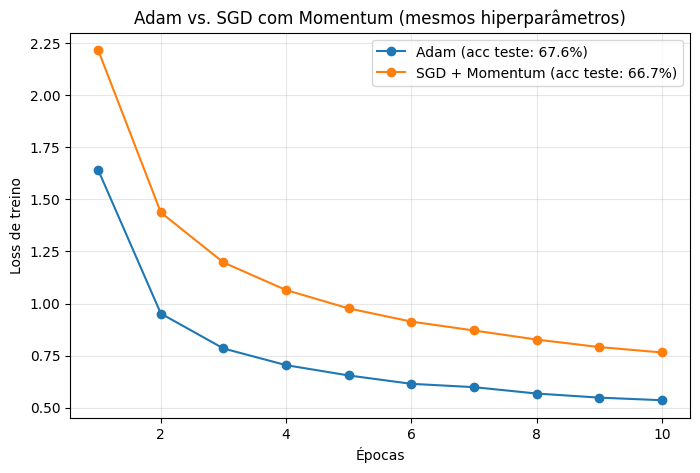

Otimizador       Loss final   Acurácia    Tempo
Adam                 0.5357     67.64%   14.5min
SGD + Momentum       0.7651     66.71%   13.4min


In [ ]:
# EXPERIMENTO: Adam vs. SGD com Momentum, mantendo os MESMOS hiperparâmetros.
# Esta célula é independente: cria um modelo NOVO para cada otimizador (para a comparação ser justa)
# e NÃO altera a variável `model` usada nas células anteriores.
import time
import numpy as np

lr_experimento = 0.001       # mesma taxa de aprendizado para os dois
epochs_experimento = epochs  # mesmo número de épocas (10)

def criar_modelo():
    # Mesma arquitetura do treino principal: ResNet18 pré-treinada, camadas congeladas, nova camada final
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for param in m.parameters():
        param.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m.to(device)

def avaliar(m):
    m.eval()
    acertos, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            preds = m(images).argmax(1)
            acertos += (preds == labels).sum().item()
            total += labels.size(0)
    return acertos / total

def treinar(nome_otimizador):
    torch.manual_seed(42)  # mesma semente: mesmos pesos iniciais da camada final e mesma ordem dos lotes
    m = criar_modelo()
    if nome_otimizador == "Adam":
        opt = optim.Adam(m.fc.parameters(), lr=lr_experimento)
    else:
        opt = optim.SGD(m.fc.parameters(), lr=lr_experimento, momentum=0.9)

    historico = []
    inicio = time.time()
    for epoch in range(epochs_experimento):
        m.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            opt.zero_grad()
            loss = criterion(m(images), labels)
            loss.backward()
            opt.step()
            running_loss += loss.item()
        historico.append(running_loss / len(train_loader))
        print(f"[{nome_otimizador}] Época {epoch+1}/{epochs_experimento} - Loss: {historico[-1]:.4f}")
    tempo = time.time() - inicio
    acc = avaliar(m)
    print(f"[{nome_otimizador}] Acurácia no teste: {acc:.2%} | Tempo: {tempo/60:.1f} min\n")
    return historico, acc, tempo

resultados = {}
for nome in ["Adam", "SGD + Momentum"]:
    resultados[nome] = treinar(nome)

# Curvas de loss lado a lado
plt.figure(figsize=(8, 5))
for nome, (hist, acc, _) in resultados.items():
    plt.plot(range(1, epochs_experimento + 1), hist, marker="o", label=f"{nome} (acc teste: {acc:.1%})")
plt.title("Adam vs. SGD com Momentum (mesmos hiperparâmetros)")
plt.xlabel("Épocas")
plt.ylabel("Loss de treino")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Tabela resumo (use estes números para preencher a nota acima)
print(f"{'Otimizador':<16} {'Loss final':>10} {'Acurácia':>10} {'Tempo':>8}")
for nome, (hist, acc, tempo) in resultados.items():
    print(f"{nome:<16} {hist[-1]:>10.4f} {acc:>10.2%} {tempo/60:>6.1f}min")

## Análise dos resultados e dos erros

### 1. Desempenho no próprio GTSRB (~67% de acerto)

Somando a diagonal da matriz de confusão, o modelo acerta cerca de **67%** das 12.630 imagens de teste do GTSRB. A loss também parou em ~0,54 após 10 épocas. Os principais erros são:

- **Limites de velocidade (classes 0 a 8):** 20, 30, 50, 60, 70, 80, 100 e 120 km/h se confundem muito entre si, porque as placas só diferem pelo número.
- **Ultrapassagem proibida (9) × Ultrapassagem proibida para caminhões (10):** os desenhos são muito parecidos.
- **Placas de advertência (triângulos, classes 18 a 31):** muitas são classificadas como *Obras na pista* (25), pois todas têm o mesmo formato e só mudam o pictograma central.

**Causa:** todas as camadas da ResNet18 foram congeladas (`requires_grad = False`) e só a última camada (`fc`) foi treinada. As features vêm do ImageNet (animais, objetos etc.) e não são específicas o bastante para separar detalhes finos como números e pictogramas pequenos. Fazer fine-tuning da rede inteira, com learning rate menor, deve elevar bastante a acurácia (no GTSRB, normalmente acima de 95%).

### 2. Desempenho nas fotos reais (4 de 13 acertos)

As fotos de teste foram tiradas no **Brasil**, mas o GTSRB contém **43 placas alemãs**. O modelo sempre escolhe uma dessas 43 classes (a softmax sempre devolve alguma resposta), mesmo quando a placa não existe no dataset:

| Foto | Previsão do modelo | Existe no GTSRB? | Resultado |
|---|---|---|---|
| Velocidade máxima 50 km/h | Limite de velocidade (50km/h) | Sim | ✅ Correto |
| PARE | Pare | Sim | ✅ Correto |
| PARE (2ª foto) | Pare | Sim | ✅ Correto |
| Semáforo à frente (losango amarelo) | Semáforo | Sim (na Alemanha é um triângulo) | ✅ Correto |
| Velocidade máxima 30 km/h "Área Escolar" | Limite de velocidade (80km/h) | Sim | ❌ Confusão entre velocidades (item 1) + texto abaixo da placa |
| Passagem de pedestres (losango amarelo) | Perigo geral | Sim (na Alemanha é um triângulo) | ❌ Formato diferente |
| Proibido estacionar "E" (vaga de deficiente) | Limite de velocidade (30km/h) | **Não** | ❌ Impossível acertar |
| Proibido estacionar "E" (curta duração) | Limite de velocidade (70km/h) | **Não** | ❌ Impossível acertar |
| Proibido parar e estacionar | Obras na pista | **Não** | ❌ Impossível acertar |
| Sentido obrigatório (seta à direita) | Ultrapassagem proibida (caminhões) | **Não** (na Alemanha é círculo azul) | ❌ Impossível acertar |
| Sentido obrigatório (seta à esquerda) | Limite de velocidade (80km/h) | **Não** (na Alemanha é círculo azul) | ❌ Impossível acertar |
| Duplo sentido de circulação | Siga em frente | **Não** | ❌ Impossível acertar |
| Proibido virar à direita (caminhões) | Limite de velocidade (30km/h) | **Não** | ❌ Impossível acertar |

**Conclusão:** das 13 fotos, **7 são de placas que não existem no GTSRB**, então o modelo nunca poderia acertá-las. Das **6 que têm equivalente**, ele acertou **4 (~67%)**, coerente com a acurácia medida no teste do GTSRB. O principal problema, portanto, não é o algoritmo, e sim a **diferença entre os dados de treino (placas alemãs) e os de uso (placas brasileiras)**. Outro fator é o enquadramento: as fotos de celular incluem poste, céu e textos auxiliares, enquanto o GTSRB contém apenas a placa recortada.

### 3. Tentativa com dataset brasileiro e melhorias futuras

Foi testado também um dataset de placas brasileiras (*Placas de Trânsito BR*, Roboflow Universe). O modelo chegou a ~85% de acerto no teste desse dataset, mas as placas que mais apareciam nas fotos (proibido estacionar, sentido obrigatório, duplo sentido) tinham pouquíssimos exemplos, e as imagens vinham de câmera veicular (placas pequenas e borradas), muito diferentes das fotos de celular. Por limitação de tempo, mantivemos o GTSRB.

Possíveis melhorias:

- **Fine-tuning da rede inteira** em vez de treinar só a última camada.
- **Dataset brasileiro maior** ou **imagens sintéticas** geradas a partir dos desenhos oficiais das placas do CTB.
- **Limiar de confiança** na softmax para responder "placa não reconhecida" em vez de forçar uma das 43 classes.
- **Recortar a placa** (manualmente ou com um detector como YOLO) antes da classificação.